# Step #1 Load the Data

In [1]:
# Time Series Forecasting - Feature Engineering for Multivariate Models
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, TensorFlow 2.21, Keras 3.15, pandas 3.0, and yfinance 1.5

import keras
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import yfinance as yf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})
keras.utils.set_random_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(tf.config.list_physical_devices('GPU'))}")

start_date = "2010-01-01"
end_date = "2026-01-01"
stock_name = "NASDAQ Composite"
symbol = "^IXIC"

df = yf.download(
    symbol,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    multi_level_index=False,
    progress=False,
)
if df.empty:
    raise RuntimeError("yfinance returned no data for the NASDAQ Composite")

print(df.shape)
df.head()

TensorFlow version: 2.21.0


Available GPUs: 0


(4024, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,2308.419922,2311.149902,2294.409912,2294.409912,1931380000
2010-01-05,2308.709961,2313.729980,2295.620117,2307.270020,2367860000
2010-01-06,2301.090088,2314.070068,2295.679932,2307.709961,2253340000
2010-01-07,2300.050049,2301.300049,2285.219971,2298.090088,2270050000
2010-01-08,2317.169922,2317.600098,2290.610107,2292.239990,2145390000


# Step #2 Explore the Data

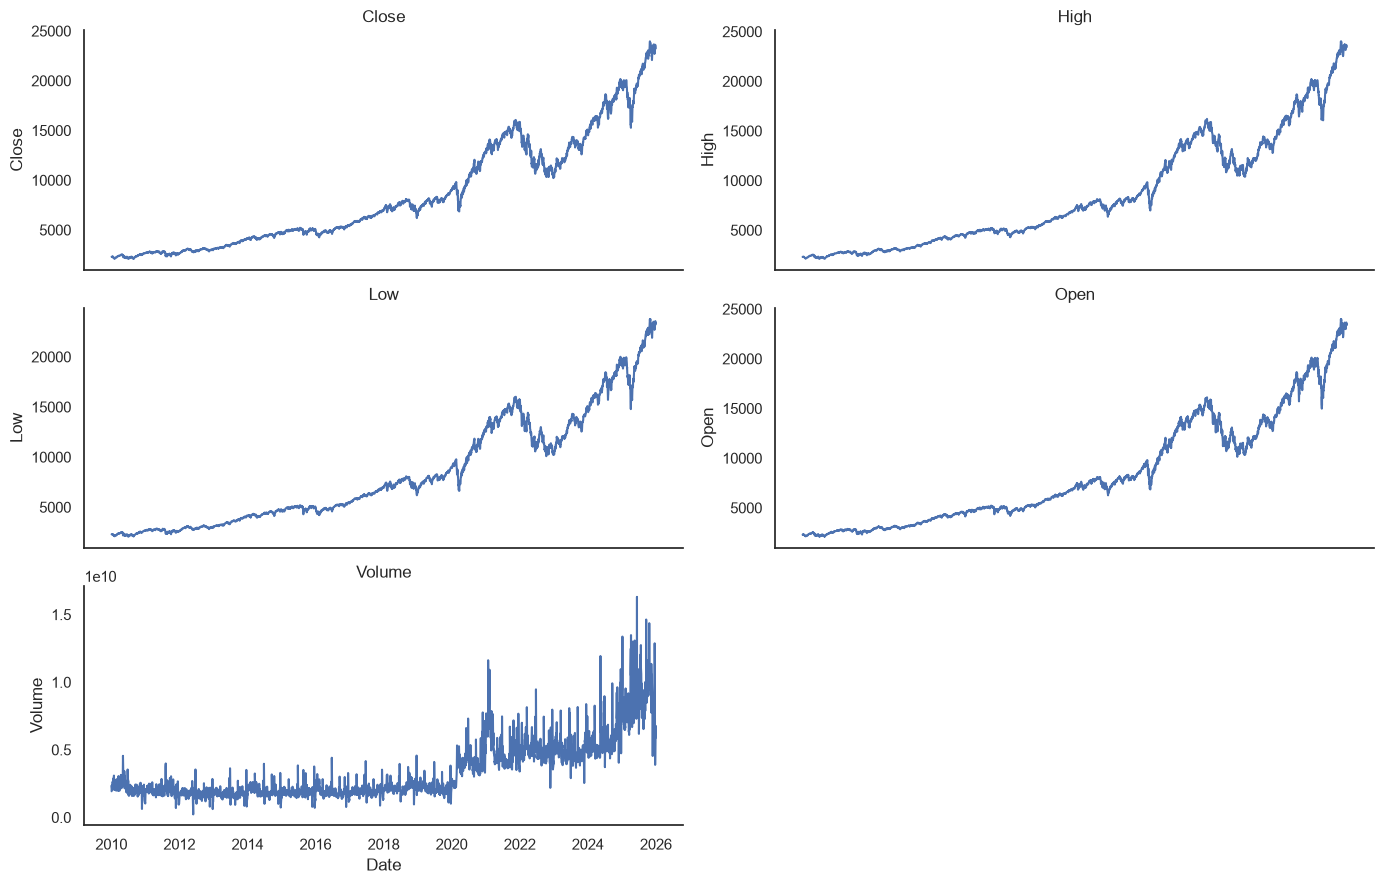

In [2]:
df_plot = df.copy()
_, axes = plt.subplots(nrows=3, ncols=2, sharex=True, figsize=(14, 9))

for ax, column in zip(axes.flat, df_plot.columns):
    sns.lineplot(x=df_plot.index, y=df_plot[column], ax=ax)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.set_title(column)

for ax in axes.flat[len(df_plot.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Step #3 Feature Engineering

In [3]:
market = df.sort_index().dropna().copy()
market.tail()

,Close,High,Low,Open,Volume
Date,,,,,
2025-12-24,23613.310547,23621.720703,23527.970703,23555.949219,3885190000
2025-12-26,23593.099609,23665.150391,23567.859375,23645.910156,5170300000
2025-12-29,23474.349609,23531.019531,23397.519531,23414.679688,6527530000
2025-12-30,23419.080078,23521.050781,23414.830078,23465.669922,6769300000
2025-12-31,23241.990234,23445.259766,23237.779297,23420.849609,5895130000


In [4]:
def create_feature_sets(market):
    price_columns = ["Open", "High", "Low", "Close"]
    price_log_returns = np.log(market[price_columns]).diff()
    volume_log_change = np.log1p(market["Volume"]).diff().rename("Volume")
    baseline = pd.concat([price_log_returns, volume_log_change], axis=1)

    close = market["Close"]
    close_return = price_log_returns["Close"]
    sma20 = close.rolling(window=20).mean()
    sma50 = close.rolling(window=50).mean()
    price_std20 = close.rolling(window=20).std()
    return_volatility20 = close_return.rolling(window=20).std()
    ema12 = close.ewm(span=12, adjust=False).mean()
    ema26 = close.ewm(span=26, adjust=False).mean()

    price_change = close.diff()
    average_gain = price_change.clip(lower=0).ewm(
        alpha=1 / 14,
        adjust=False,
        min_periods=14,
    ).mean()
    average_loss = (-price_change.clip(upper=0)).ewm(
        alpha=1 / 14,
        adjust=False,
        min_periods=14,
    ).mean()
    relative_strength = average_gain / average_loss

    technical = pd.DataFrame(
        {
            "Intraday_Range": np.log(market["High"] / market["Low"]),
            "Open_to_Close": np.log(close / market["Open"]),
            "SMA20_Distance": close / sma20 - 1,
            "SMA50_Distance": close / sma50 - 1,
            "Return_Volatility20": return_volatility20,
            "Bollinger_Position": (close - sma20) / (2 * price_std20),
            "RSI14": (100 - 100 / (1 + relative_strength)) / 100,
            "MACD_Spread": (ema12 - ema26) / close,
        },
        index=market.index,
    )

    engineered = pd.concat([baseline, technical], axis=1)
    engineered = engineered.replace([np.inf, -np.inf], np.nan).dropna()
    baseline = baseline.loc[engineered.index]
    return baseline, engineered


baseline_features, engineered_features = create_feature_sets(market)
assert baseline_features.index.equals(engineered_features.index)
assert np.isfinite(engineered_features.to_numpy()).all()

print(f"Baseline shape: {baseline_features.shape}")
print(f"Engineered shape: {engineered_features.shape}")
print(f"Common dates: {engineered_features.index.min().date()} -> {engineered_features.index.max().date()}")

Baseline shape: (3975, 5)
Engineered shape: (3975, 13)
Common dates: 2010-03-16 -> 2025-12-31


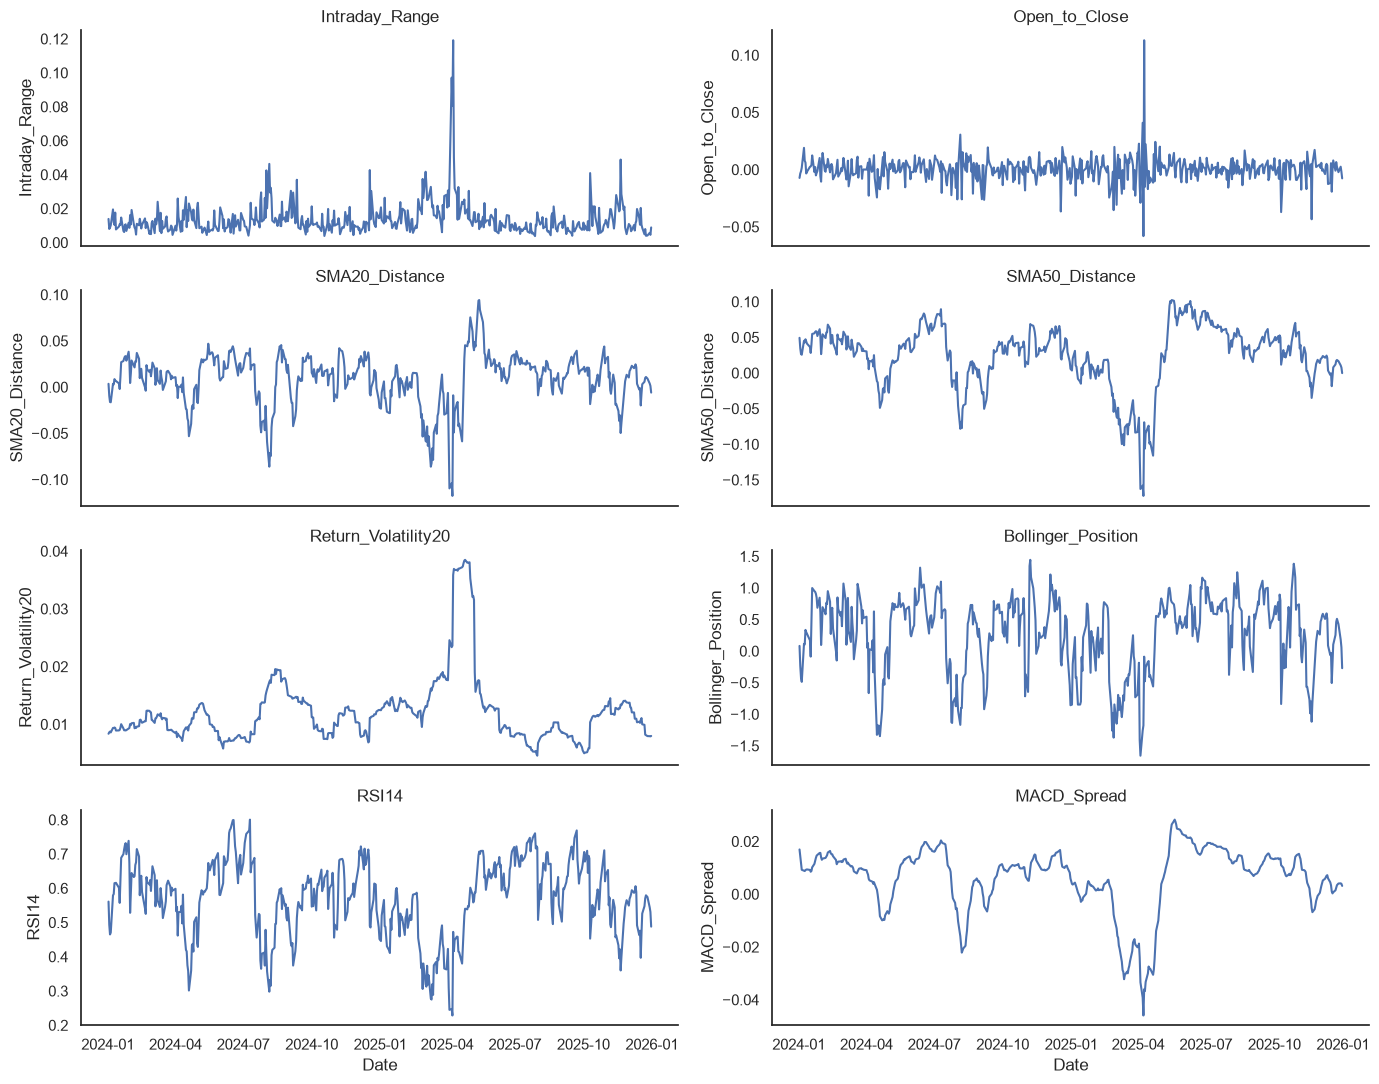

,Open,High,Low,Close,Volume,Intraday_Range,Open_to_Close,SMA20_Distance,SMA50_Distance,Return_Volatility20,Bollinger_Position,RSI14,MACD_Spread
Date,,,,,,,,,,,,,
2025-12-24,0.006313,0.002469,0.006416,0.002182,-0.660154,0.003977,0.002432,0.010945,0.018258,0.008112,0.510021,0.579297,0.003403
2025-12-26,0.003812,0.001837,0.001694,-0.000856,0.285759,0.004120,-0.002236,0.009263,0.016578,0.007957,0.427005,0.574280,0.004035
2025-12-29,-0.009827,-0.005684,-0.007254,-0.005046,0.233098,0.005690,0.002545,0.003949,0.010667,0.007942,0.181451,0.544444,0.004101
2025-12-30,0.002175,-0.000424,0.000740,-0.002357,0.036369,0.004526,-0.001987,0.001279,0.007646,0.007908,0.059046,0.530625,0.003911
2025-12-31,-0.001912,-0.003227,-0.007590,-0.007591,-0.138271,0.008889,-0.007666,-0.005928,-0.000190,0.007981,-0.271368,0.487897,0.003131


In [5]:
technical_columns = [
    column
    for column in engineered_features.columns
    if column not in baseline_features.columns
]
feature_preview = engineered_features.loc["2024-01-01":, technical_columns]
_, axes = plt.subplots(nrows=4, ncols=2, sharex=True, figsize=(14, 11))

for ax, column in zip(axes.flat, technical_columns):
    sns.lineplot(x=feature_preview.index, y=feature_preview[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()
engineered_features.tail()

# Step #4 Scaling and Transforming the Data

In [6]:
close_returns = baseline_features[["Close"]].to_numpy()
close_levels = market.loc[baseline_features.index, "Close"].to_numpy()
train_size = int(len(baseline_features) * 0.8)

baseline_scaler = RobustScaler()
baseline_scaler.fit(baseline_features.iloc[:train_size])
scaled_baseline = baseline_scaler.transform(baseline_features)

engineered_scaler = RobustScaler()
engineered_scaler.fit(engineered_features.iloc[:train_size])
scaled_engineered = engineered_scaler.transform(engineered_features)

target_scaler = RobustScaler()
target_scaler.fit(close_returns[:train_size])
scaled_close_returns = target_scaler.transform(close_returns)

print(f"Training rows: {train_size}")
print(f"Test rows: {len(baseline_features) - train_size}")
print(f"First test date: {baseline_features.index[train_size].date()}")

Training rows: 3180
Test rows: 795
First test date: 2022-10-31


In [7]:
sequence_length = 50


def create_sequences(feature_values, target_values, sequence_length):
    inputs, targets, target_indices = [], [], []
    for target_index in range(sequence_length, len(feature_values)):
        inputs.append(feature_values[target_index - sequence_length:target_index])
        targets.append(target_values[target_index, 0])
        target_indices.append(target_index)

    return (
        np.asarray(inputs, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(target_indices),
    )


x_baseline_all, y_all, target_indices = create_sequences(
    scaled_baseline,
    scaled_close_returns,
    sequence_length,
)
x_engineered_all, _, engineered_target_indices = create_sequences(
    scaled_engineered,
    scaled_close_returns,
    sequence_length,
)
assert np.array_equal(target_indices, engineered_target_indices)

train_mask = target_indices < train_size
test_mask = target_indices >= train_size
x_baseline_train = x_baseline_all[train_mask]
x_baseline_test = x_baseline_all[test_mask]
x_engineered_train = x_engineered_all[train_mask]
x_engineered_test = x_engineered_all[test_mask]
y_train, y_test = y_all[train_mask], y_all[test_mask]
test_target_indices = target_indices[test_mask]

print(f"Baseline training shape: {x_baseline_train.shape}")
print(f"Engineered training shape: {x_engineered_train.shape}")
print(f"Test target shape: {y_test.shape}")
assert test_target_indices[0] == train_size
print(
    "First test target:",
    baseline_features.index[test_target_indices[0]].date(),
    "using data through",
    baseline_features.index[test_target_indices[0] - 1].date(),
)

Baseline training shape: (3130, 50, 5)
Engineered training shape: (3130, 50, 13)
Test target shape: (795,)
First test target: 2022-10-31 using data through 2022-10-28


# Step #5 Model Training

Baseline parameters: 5,409
Engineered parameters: 6,433
Baseline epochs: 4
Engineered epochs: 7


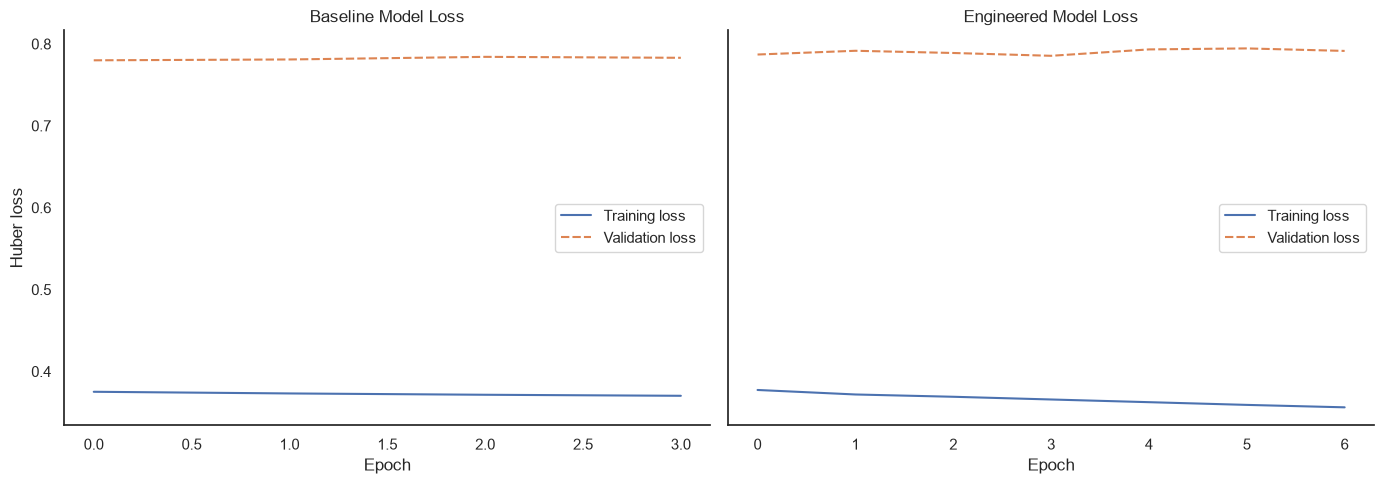

In [8]:
def build_and_train_model(x_train, name):
    keras.utils.set_random_seed(42)
    model = keras.Sequential(
        [
            keras.layers.Input(shape=(sequence_length, x_train.shape[2])),
            keras.layers.LSTM(32),
            keras.layers.Dense(16, activation="relu"),
            keras.layers.Dense(1),
        ],
        name=name,
    )
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss=keras.losses.Huber(),
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    )
    history = model.fit(
        x_train,
        y_train,
        batch_size=32,
        epochs=20,
        validation_split=0.1,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0,
    )
    return model, history


baseline_model, baseline_history = build_and_train_model(
    x_baseline_train,
    "nasdaq_baseline_lstm",
)
engineered_model, engineered_history = build_and_train_model(
    x_engineered_train,
    "nasdaq_engineered_lstm",
)

print(f"Baseline parameters: {baseline_model.count_params():,}")
print(f"Engineered parameters: {engineered_model.count_params():,}")
print(f"Baseline epochs: {len(baseline_history.history['loss'])}")
print(f"Engineered epochs: {len(engineered_history.history['loss'])}")

_, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), sharey=True)
for ax, label, history in (
    (axes[0], "Baseline", baseline_history),
    (axes[1], "Engineered", engineered_history),
):
    loss_frame = pd.DataFrame(
        {
            "Training loss": history.history["loss"],
            "Validation loss": history.history["val_loss"],
        }
    )
    sns.lineplot(data=loss_frame, ax=ax)
    ax.set_title(f"{label} Model Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Huber loss")

plt.tight_layout()
plt.show()

# Step #6 Evaluate Model Performance

Positive-return test sessions: 56.7%
Majority-class directional baseline: 56.7%


,Price MAE,Price RMSE,Return MAE (bps),Directional accuracy (%)
Model,,,,
Baseline LSTM,148.49,213.04,91.80,56.86
Engineered LSTM,149.08,213.85,92.18,56.73
Persistence,150.85,213.73,93.14,0.00
Median drift,149.28,213.29,92.27,56.73


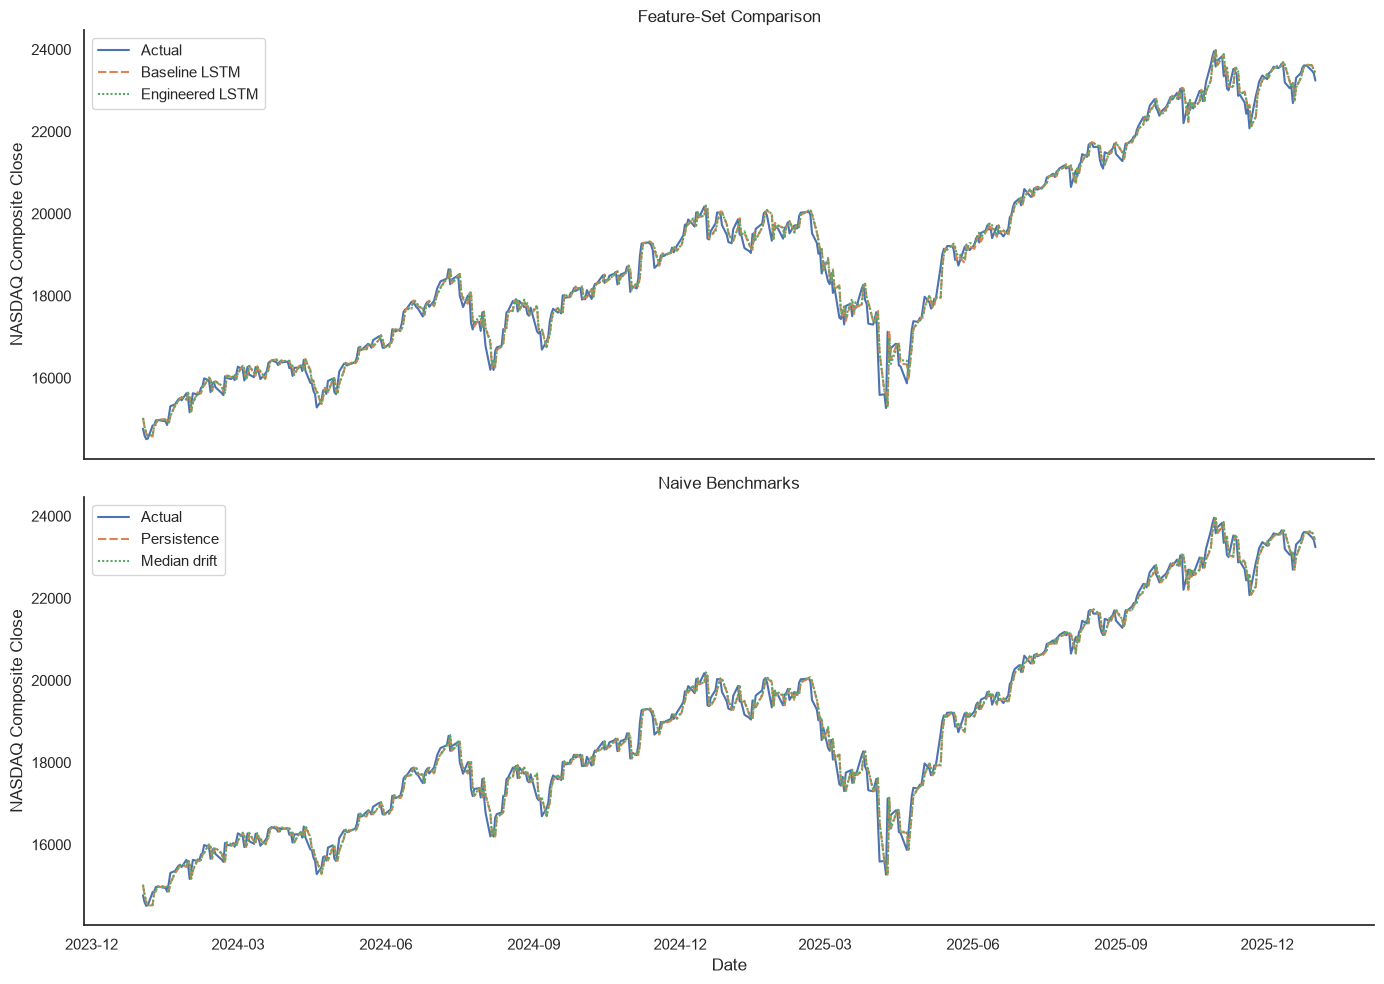

In [9]:
baseline_scaled_predictions = baseline_model.predict(x_baseline_test, verbose=0)
engineered_scaled_predictions = engineered_model.predict(x_engineered_test, verbose=0)
baseline_return_predictions = target_scaler.inverse_transform(
    baseline_scaled_predictions
).ravel()
engineered_return_predictions = target_scaler.inverse_transform(
    engineered_scaled_predictions
).ravel()
actual_returns = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

actual_prices = close_levels[test_target_indices]
previous_prices = close_levels[test_target_indices - 1]
median_training_return = float(np.median(close_returns[:train_size]))

predictions = {
    "Baseline LSTM": baseline_return_predictions,
    "Engineered LSTM": engineered_return_predictions,
    "Persistence": np.zeros_like(actual_returns),
    "Median drift": np.full_like(actual_returns, median_training_return),
}

metric_rows = []
predicted_prices = {}
for name, predicted_returns in predictions.items():
    prices = previous_prices * np.exp(predicted_returns)
    predicted_prices[name] = prices
    metric_rows.append(
        {
            "Model": name,
            "Price MAE": mean_absolute_error(actual_prices, prices),
            "Price RMSE": root_mean_squared_error(actual_prices, prices),
            "Return MAE (bps)": mean_absolute_error(
                actual_returns, predicted_returns
            ) * 10_000,
            "Directional accuracy (%)": np.mean(
                np.sign(actual_returns) == np.sign(predicted_returns)
            ) * 100,
        }
    )

metrics = pd.DataFrame(metric_rows).set_index("Model").round(2)
positive_return_rate = np.mean(actual_returns > 0) * 100
majority_class_accuracy = max(positive_return_rate, 100 - positive_return_rate)
print(f"Positive-return test sessions: {positive_return_rate:.1f}%")
print(f"Majority-class directional baseline: {majority_class_accuracy:.1f}%")
display(metrics)

results = pd.DataFrame(
    {"Actual": actual_prices, **predicted_prices},
    index=baseline_features.index[test_target_indices],
)
plot_results = results.loc["2024-01-01":]
_, axes = plt.subplots(nrows=2, ncols=1, figsize=(14, 10), sharex=True, sharey=True)
sns.lineplot(
    data=plot_results[["Actual", "Baseline LSTM", "Engineered LSTM"]],
    ax=axes[0],
)
axes[0].set_title("Feature-Set Comparison")
sns.lineplot(
    data=plot_results[["Actual", "Persistence", "Median drift"]],
    ax=axes[1],
)
axes[1].set_title("Naive Benchmarks")
for ax in axes:
    ax.set_ylabel(f"{stock_name} Close")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.tight_layout()
plt.show()

## Conclusion

The engineered indicators do not improve this one-session-ahead forecast. On the shared test period, the five-feature LSTM has a slightly lower price MAE than both the 13-feature model and the median-drift benchmark. Its directional accuracy is also effectively equal to the 56.7% majority-class baseline.

This does not mean that technical indicators are always useless. It shows why feature engineering should be treated as a testable hypothesis: calculate features causally, compare them on identical dates, fit preprocessing on training data only, and retain the extra complexity only when it improves out-of-sample performance.